calling GenPaths.py from: .../daaps/pythonModelling/DAAPS_TOOLKIT/GenPaths.py
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/FittingTools
Added to path: /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel
global path variables:
	 PROJECT_PATH =.../.../vera/daaps/pythonModelling/DAAPS_TOOLKIT
	 OPTICS_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA
	 LITERATURE_DATA_PATH =.../.../daaps/pythonModelling/DAAPS_TOOLKIT/literatureDATA
	 VERA_DATA_PATH =.../.../projects/vera/daaps/veraData
------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


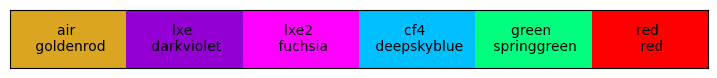

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter1d
import time

from scipy import optimize as opt
from scipy import stats as sps
import iminuit
from iminuit import Minuit

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
from PDEModel.PhotonInfo import * # this calls DataLoader when defining init
from PDEModel import PNJunction as PNJ

import FittingTools.FittingFunctions as FF
from FittingTools.FittingFunctions import *

import FittingTools.PDE_fittingTools as SS

from cycler import cycler


MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
# ms.SetMPLcolors() # turn off with "off" option

rad2deg = 180/np.pi

$$ T_{window} = \frac{A~T_{12}~T_{21}}{1 - (A R_{21})^2} $$


$$ T_{12} = \frac{n_2 \cos\theta_2}{n_1 \cos\theta_1} |t_{12}|^2$$
$$ T_{21} = \frac{n_1 \cos\theta_1}{n_2 \cos\theta_2} |t_{21}|^2$$

$$T_{12}T_{21} = \frac{n_2 \cos\theta_2}{n_1 \cos\theta_1} |t_{12}|^2 \cdot \frac{n_1 \cos\theta_1}{n_2 \cos\theta_2} |t_{21}|^2 = |t_{12}|^2 |t_{21}|^2$$

In [11]:
from scipy.optimize import minimize
from scipy.stats import norm
import numpy as np

dhToMaximize = OpticsData()
mediaToMaximize = "lxe"

def TransmissionWrapper(thickness, angle, wlen):
    photon = PI.PhotonInfo(wlen, angle, dataHelper=dhToMaximize, mediumStr=mediaToMaximize)
    return photon.Wave_TotalTransmission(thickness)
  
def TransmissionWrapper_RayOptics(thickness, angle, wlen):
    photon = PI.PhotonInfo(wlen, angle, dataHelper=dhToMaximize, mediumStr=mediaToMaximize)
    return photon.Ray_T13(thick_oxide = thickness)

def TransmissionWrapper2(thickness, angle, wlen, medium):
    photon = PI.PhotonInfo(wlen, angle, dataHelper=dhToMaximize, mediumStr=medium)
    return photon.Wave_TotalTransmission(thickness)

def TransmissionWrapper_min_named(thickness, angle, wlen):
    trans = TransmissionWrapper(thickness, angle, wlen)
    return np.log(1-trans)

def TransmissionWrapper_min(params):
    thickness, angle, wlen = params  # Unpack the array into individual variables
    Trans = TransmissionWrapper(thickness, angle, wlen)
    return np.log(1-Trans)

# for a given spectral width
def TransmissionWrapper_named_averaged(thickness, angle, wlen, fwhm):
    gausX = np.linspace(wlen-2*fwhm, wlen+2*fwhm, 20)
    gausY = norm.pdf(gausX, loc=wlen, scale=fwhm/2.355)
    # print(gausY)
    TransVals = np.array([TransmissionWrapper(thickness, angle, wl) for wl in gausX])
    # print(TransVals)
    weightedTrans = np.sum(gausY * TransVals)/np.sum(gausY)
    return weightedTrans

# for a given spectral width
def TransmissionWrapper_named_averaged2(thickness, angle, wlen, fwhm, medium):
    gausX = np.linspace(wlen-2*fwhm, wlen+2*fwhm, 20)
    gausY = norm.pdf(gausX, loc=wlen, scale=fwhm/2.355)
    # print(gausY)
    TransVals = np.array([TransmissionWrapper2(thickness, angle, wl, medium) for wl in gausX])
    # print(TransVals)
    weightedTrans = np.sum(gausY * TransVals)/np.sum(gausY)
    return weightedTrans

tvac = TransmissionWrapper_named_averaged2(1359, 0, 176, 10, "vacuum")
tlxe = TransmissionWrapper_named_averaged2(1359, 0, 176, 10, "LXe")
# Ray_T13
print("Transmission in vacuum", tvac)
print("Transmission in LXe", tlxe)
print("Ray optics transmission in vacuum", TransmissionWrapper_RayOptics(1359, 0, 176))
print("---")

# for a given spectral width
def TransmissionWrapper_min_named_averaged(thickness, angle, wlen, fwhm):
    avgT = TransmissionWrapper_named_averaged(thickness, angle, wlen, fwhm)
    return np.log(1-avgT)

print("test value",TransmissionWrapper(16.8, 0, 120))
print("test value",TransmissionWrapper(16.8, 0, 128))
print("test value",TransmissionWrapper(16.8, 0, 136))

Transmission in vacuum (0.3811258298850108+0j)
Transmission in LXe (0.3898031617683808+0j)
Ray optics transmission in vacuum 0.389780772926558
---
test value (0.032122887720150727+0j)
test value (0.1739278861513442+0j)
test value (0.32898440724782474+0j)


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1762: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/matplotlib/cbook.py:1398: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


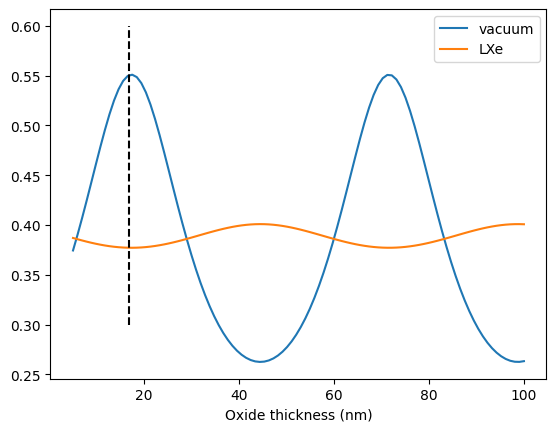

In [3]:
## plotting vs oxide thickness
xthick = np.linspace(5, 100, 100)

plt.plot(xthick, TransmissionWrapper2(xthick, 0, 175, "vacuum"), label="vacuum")
plt.plot(xthick, TransmissionWrapper2(xthick, 0, 175, "LXe"), label="LXe")

plt.vlines(16.8, 0.3, 0.6, color='k', linestyle='--')

plt.xlabel("Oxide thickness (nm)")
plt.legend()

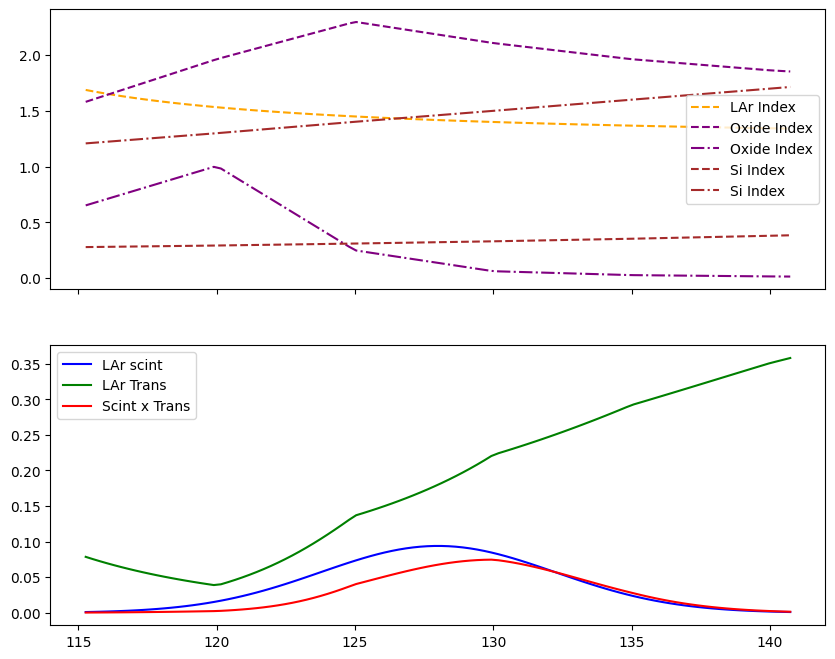

average transmission (0.18007333530355754+0j)
single line transmission (0.17996100379206786+0j)
(0.18022391774952248+0j)


In [4]:
# Define parameters for the Gaussian using built-in functions
mean = 128
fwhm = 10
std_dev = fwhm / 2.355 # Convert FWHM to standard deviation
gausX = np.linspace(mean - 3*std_dev, mean + 3*std_dev, 100)
gausY = norm.pdf(gausX, loc=mean, scale=std_dev)

larTrans = TransmissionWrapper(16.8, 0, gausX)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

ax1.plot(gausX, dhToMaximize.LArIndex(gausX), linestyle = "--", label='LAr Index', color='orange')
ax1.plot(gausX, dhToMaximize.OxideIndex(gausX).real, linestyle = "--", label='Oxide Index', color='purple')
ax1.plot(gausX, dhToMaximize.OxideIndex(gausX).imag, linestyle = "-.", label='Oxide Index', color='purple')
ax1.plot(gausX, dhToMaximize.SiIndex(gausX).real, linestyle = "--", label='Si Index', color='brown')
ax1.plot(gausX, dhToMaximize.SiIndex(gausX).imag, linestyle = "-.", label='Si Index', color='brown')
ax1.legend()

ax2.plot(gausX, gausY, label='LAr scint', color='blue')
ax2.plot(gausX, larTrans, label='LAr Trans', color='green')
ax2.plot(gausX, 4*gausY*larTrans, label='Scint x Trans', color='red')
ax2.legend()

plt.show()

print("average transmission", np.sum(gausY*larTrans)/np.sum(gausY))
print("single line transmission", TransmissionWrapper(16.8, 0, 128))
print(TransmissionWrapper_named_averaged(16.8, 0, 128, 10))

In [5]:

## maximizer
# for thisWlen in wlenToMaximize:
    
#     # Initial guesses for thickness, angle, and wavelength
#     initial_guess = [1500, 45, thisWlen]
    
#     # Define the bounds for x, y, z
#     bounds = [(5, 4000),    # bounds for thickness
#               (0, 85),     # bounds for angle
#               (thisWlen, thisWlen) # bounds for wavelength
#               ]
#     # Using iminuit to minimize the function
#     result = iminuit.minimize(TransmissionWrapper_min, x0=initial_guess, bounds=bounds, method='migrad')
#     # result = m.migrad()  # Perform the minimization

#     xRes = result.x
#     # print(xRes)

#     print("best transmission for wlen = {:.0f} nm: tox = {:.2f} nm, theta = {:.2f} deg".format(xRes[2], xRes[0], xRes[1]))
#     print("AOI:", TransmissionWrapper(xRes[0], xRes[1], xRes[2]).round(4))
#     print("normal:", TransmissionWrapper(xRes[0], 0, xRes[2]).round(4))

## single wavelength loop
# loop
wlenToMaximize = [532, 589, 637, 780, 795, 850]

print("submerged in", mediaToMaximize)
## scanner
for thisWlen in wlenToMaximize:
    m = Minuit(TransmissionWrapper_min_named, thickness=100, angle=0, wlen=thisWlen)
    m.fixed["wlen"] = True
    
    m.fixed["angle"] = True
    m.limits["thickness"] = (10, 1000)
    
    resThick = m.scan(ncall=1000)
    print(f"best transmission for wlen = {thisWlen:.0f} nm: tox = {resThick.values['thickness']:.2f} nm, theta = {resThick.values['angle']:.2f} deg")
    T1d = TransmissionWrapper(resThick.values['thickness'], resThick.values['angle'], thisWlen)
    print("Trans:", T1d.round(4))
    
    m.reset()
    #######
    m.fixed["angle"] = False
    m.limits["angle"] = (0, 65)
    m.values["thickness"] = 100
    
    resBoth = m.scan(ncall=1000)
    T2d = TransmissionWrapper(resBoth.values['thickness'], resBoth.values['angle'], thisWlen)
    if T2d > T1d + 0.01:
        print("2D scan better")
        print(f"best transmission for wlen = {thisWlen:.0f} nm: tox = {resBoth.values['thickness']:.2f} nm, theta = {resBoth.values['angle']:.2f} deg")
        print("Trans:", T2d.round(4))
    
    print("-- --")

submerged in cf4
best transmission for wlen = 532 nm: tox = 91.26 nm, theta = 0.00 deg
Trans: (0.8323+0j)
-- --


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py:945: ComplexWarning: Casting complex values to real discards the imaginary part
  r = self._fcn(x[: self.npar])
/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/iminuit/minuit.py:964: ComplexWarning: Casting complex values to real discards the imaginary part
  fm = FunctionMinimum(self._fcn, self._last_state, self.strategy, edm_goal)


best transmission for wlen = 589 nm: tox = 101.17 nm, theta = 0.00 deg
Trans: (0.8473+0j)
-- --
best transmission for wlen = 637 nm: tox = 328.11 nm, theta = 0.00 deg
Trans: (0.8565+0j)
-- --
best transmission for wlen = 780 nm: tox = 670.99 nm, theta = 0.00 deg
Trans: (0.8726+0j)
-- --
best transmission for wlen = 795 nm: tox = 410.36 nm, theta = 0.00 deg
Trans: (0.8737+0j)
-- --
best transmission for wlen = 850 nm: tox = 731.44 nm, theta = 0.00 deg
Trans: (0.8769+0j)
-- --


In [6]:
print("submerged in", mediaToMaximize)
# sline = TransmissionWrapper(16.8, 0, 128)
# print("single line transmission", sline)

ft1 = TransmissionWrapper_named_averaged2(15, 0, 128, 10, "LAr")
ft2 = TransmissionWrapper_named_averaged2(17.2, 0, 128, 10, "vacuum")

print("average transmission", ft1)
print("avarage transmission vacuum", ft2)

dhFranta = ODL.OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))

fulPDE = FF.PDE_allArgs_wlen_parametrized_forMedium(wlen=128, theta1=0, FF=0.6, tOxide=16.8, dp_star=0.1, Xpn=1e3, dw_star=5e3,
                                                    voltage=4., Ve=1.6, Vh=10, Ae=1.0, Ah=0.0, Temperature = None, smoothSigma=None,
                                                    quantum = False, dh = None, window=False, medium="lar")

fulPDE_franta = FF.PDE_allArgs_wlen_parametrized_forMedium(wlen=128, theta1=0, FF=0.6, tOxide=16.8, dp_star=0.5, Xpn=1e3, dw_star=5e3,
                                                    voltage=4., Ve=1.6, Vh=10, Ae=1.0, Ah=0.0, Temperature = None, smoothSigma=None,
                                                    quantum = False, dh = dhFranta, window=False, medium="lar")


print("full PDE", fulPDE)
print("full PDE Franta", fulPDE_franta)

# def avgPDE_wrapper(wlen, fwhm, theta1, FF, tOxide, dp_star, Xpn, dw_star, voltage, Ve, Vh, Ae=1.0, Ah=1.0, Temperature = None, smoothSigma=None, quantum = False, dh = None, window=False, medium="vacuum"):
#     gausX = np.linspace(wlen-2*fwhm, wlen+2*fwhm, 20)
#     gausY = norm.pdf(gausX, loc=wlen, scale=fwhm/2.355)
#     # print(gausY)
#     pdevals = np.array([
#         PDE_allArgs_wlen_parametrized_forMedium(wlen=wl, theta1=theta1, FF=FF, tOxide=tOxide, dp_star=dp_star, Xpn=Xpn, dw_star=dw_star,
#                                                     voltage=voltage, Ve=Ve, Vh=Vh, Ae=Ae, Ah=Ah, Temperature = Temperature, smoothSigma=smoothSigma,
#                                                     quantum = quantum, dh = dh, window=window, medium=medium) for wl in gausX])
#     meanPDE = np.sum(gausY * pdevals)/np.sum(gausY)
#     return meanPDE

# avgPDE = avgPDE_wrapper(wlen = 128, fwhm = 10, theta1=0, FF=0.6, tOxide=16.8, dp_star=1.2, Xpn=1e3, dw_star=5e3,
#                         voltage=4., Ve=1.6, Vh=10, Ae=1.0, Ah=0.0, Temperature = None, smoothSigma=None,
#                         quantum = False, dh = None, window=False, medium="lar")
# print("average PDE", avgPDE)


submerged in cf4
average transmission (0.21115830100047825+0j)
avarage transmission vacuum (0.15392426585944913+0j)
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/opticsDATA/Franta_data/Franta-150K.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_dioxide-merged-clear.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Silicon data from
   /Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/pythonModelling/DAAPS_TOOLKIT/PDEModel/../opticsData/GoodMerged/silicon_merged_AspnesMiddle.txt
loaded and interpolated successfully.
-----------------------------
-----------------------------
Oxide data from
   /Users/austindestcro

In [7]:
## spectral loop
# loop
spectraToMaximize = [[128, 10], [175, 10], [430, 80]]

## scanner
print("submerged in ", mediaToMaximize)
for thisWlen in spectraToMaximize:
    
    slineTrans = TransmissionWrapper(17.2, 0, thisWlen[0])
    fullTrans = TransmissionWrapper_named_averaged(17.2, 0, thisWlen[0], thisWlen[1])
    print(thisWlen)
    print("single line transmission", slineTrans.round(3), " for thickness 17.2 nm")
    print("averaged transmission", fullTrans.round(3))
    
    # continue
    m = Minuit(TransmissionWrapper_min_named_averaged, thickness=10, angle=0, wlen=thisWlen[0], fwhm=thisWlen[1])
    m.fixed["wlen"] = True
    m.fixed["fwhm"] = True
    m.fixed["angle"] = True
    
    m.limits["thickness"] = (0, 100)
    
    resThick = m.scan(ncall=2000)
    TransmissionWrapper_named_averaged
    T1d = TransmissionWrapper_named_averaged(thickness=resThick.values['thickness'], angle=resThick.values['angle'], wlen=thisWlen[0], fwhm=thisWlen[1])
    
    print(f"best transmission for wlen = {thisWlen[0]:.0f} nm: tox = {resThick.values['thickness']:.2f} nm, theta = {resThick.values['angle']:.2f} deg")
    print("Trans:", T1d.round(4))
    print("--------\n")
    m.reset()

submerged in  cf4
[128, 10]
single line transmission (0.177+0j)  for thickness 17.2 nm
averaged transmission (0.177+0j)
best transmission for wlen = 128 nm: tox = 4.05 nm, theta = 0.00 deg
Trans: (0.4006+0j)
--------

[175, 10]
single line transmission (0.474+0j)  for thickness 17.2 nm
averaged transmission (0.474+0j)
best transmission for wlen = 175 nm: tox = 17.26 nm, theta = 0.00 deg
Trans: (0.4738+0j)
--------

[430, 80]
single line transmission (0.651+0j)  for thickness 17.2 nm
averaged transmission (0.639+0j)
best transmission for wlen = 430 nm: tox = 71.44 nm, theta = 0.00 deg
Trans: (0.7592+0j)
--------



In [8]:
def Wp_wrapper(wlen, dp, Xpn):
    
    pnj = PNJ.PNJunction(tOxide=16.8, dp_star = dp, Xpn = Xpn, dw_star = 2*Xpn)
    photon = PI.PhotonInfo(wlen, 0, dataHelper=dhToMaximize, mediumStr=mediaToMaximize)
    Wp = pnj.calcWp(photon)
    return Wp

print(Wp_wrapper(430, 5, 2e3))

for wl in wlenToMaximize:
    Xpn_start = 0.2e3
    Wp = Wp_wrapper(wl, 10, Xpn_start)
    # print("Wp = {:.2f} for wl = {:.0f} nm".format(Wp, wl))
    jump = 10
    while Wp < 0.7:
        Wp = Wp_wrapper(wl, 10, Xpn_start)
        # print("Wp = {:.2f} for wl = {:.0f} nm".format(Wp, wl))
        Xpn_start += jump
    print("Xpn = {:.2f} um for wl = {:.0f} nm".format(Xpn_start/1.e3, wl))

for wls in spectraToMaximize:
    wl = wls[0]
    dp_start = 5
    Wp = Wp_wrapper(wl, dp_start, 1e3)
    # print("Wp = {:.2f} for wl = {:.0f} nm".format(Wp, wl))
    jump = 0.1
    
    while Wp < 0.9:
        Wp = Wp_wrapper(wl, dp_start, 0.2e3)
        # print("Wp = {:.2f} for wl = {:.0f} nm".format(Wp, wl))
        dp_start -= jump
    print("dp = {:.2f} nm for wl = {:.0f} nm".format(dp_start, wl))

(0.971624235262578+0j)
Xpn = 0.93 um for wl = 532 nm
Xpn = 1.76 um for wl = 589 nm
Xpn = 2.99 um for wl = 637 nm
Xpn = 11.92 um for wl = 780 nm
Xpn = 13.91 um for wl = 795 nm
Xpn = 23.56 um for wl = 850 nm
dp = 0.60 nm for wl = 128 nm
dp = 0.50 nm for wl = 175 nm
dp = 5.00 nm for wl = 430 nm
